# Expériences — Solveur $v_1^{LD}$ C++/DP sur les instances CovSet

Trois tailles d'instances (small / medium / large), deux variantes du solveur C++/DP (`v1ld_cpp2`) :

| Variante | Sous-problème ζ_i | Complexité / itération |
|---|---|---|
| **$v_1^{LD}$ exact** (`decomp=False`) | Bitmask DP, O(n·2^m) | ~O(n·2^m·N) |
| **$v_1^{LD}$ décomp.** (`decomp=True`) | Glouton 1-contrainte + ν, O(n·m) | ~O(n·m·N) |

Référence : relaxation LP du CCSP.

In [1]:
import sys, os, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

sys.path.insert(0, ".")
import v1ld_cpp2
from solver.instance_reader import load_instances
from solver.mip_reference import solve_mip_exact
from run_tests import solve_lp_relaxation_ccsp

os.makedirs("figures_cpp", exist_ok=True)

# ── Wrappers ──────────────────────────────────────────────────
def _np_arrays(inst):
    return (np.array(inst.c, dtype=np.float64),
            np.array(inst.p, dtype=np.float64),
            np.array(inst.A, dtype=np.float64),
            np.array(inst.b, dtype=np.float64))

def solve_cpp2(inst, T=500, decomp=True, verbose=False):
    """C++/DP (v1ld_cpp2)."""
    c, p, A, b = _np_arrays(inst)
    return v1ld_cpp2.solve(c, p, A, b, inst.epsilon, T, decomp, verbose)

# ── Constantes ──────────────────────────────────────────────
EPSILON   = 0.1
N_INST    = 10
T_QUALITY = 1000
T_VALUES  = [10, 25, 50, 100, 200, 500, 1000]
T_CONV    = 2000
N_CONV    = 3
DATA_DIR  = "data/covset/datasets/test"

SIZES = {
    "small":  f"{DATA_DIR}/ccsp-test-small.txt",
    "medium": f"{DATA_DIR}/ccsp-test-medium.txt",
    "large":  f"{DATA_DIR}/ccsp-test-large.txt",
}
PALETTE = {"small": "#2563eb", "medium": "#16a34a", "large": "#dc2626"}

plt.rcParams.update({
    "font.family": "serif", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 130,
})

In [2]:
# ── Chargement des instances ─────────────────────────────────
instances_all = {}
for size, path in SIZES.items():
    insts = load_instances(path, epsilon=EPSILON, max_episodes=N_INST)
    instances_all[size] = insts
    f = insts[0]
    print(f"{size:8s}: {len(insts)} instances  n={f.n}, m={f.m}, N={f.N}")

small   : 10 instances  n=20, m=5, N=5
medium  : 10 instances  n=50, m=5, N=10
large   : 10 instances  n=50, m=5, N=20


## 1. Qualité des bornes

Pour chaque taille (small / medium / large) et chaque instance, on calcule :
- `v*` : optimal MIP (PuLP/CBC)
- `v_LP` : relaxation LP du CCSP
- `C++/DP décomp` : v1ld_cpp2, décomposition ν (decomp=True)
- `C++/DP exact` : v1ld_cpp2, bitmask DP O(n·2^m) pour ζ_i (decomp=False)

Gap relatif : $(v^* - \hat{v}) / v^*$

In [3]:
results_q = {}

for size in SIZES:
    print(f"\n── {size.upper()} (T={T_QUALITY}) ──")
    rows = []

    for inst in instances_all[size]:
        ep = inst.episode

        v_mip, status = solve_mip_exact(inst)
        if status != "Optimal":
            print(f"  ep {ep}: MIP={status}, skip")
            continue

        v_lp = solve_lp_relaxation_ccsp(inst)
        if v_lp is None:
            print(f"  ep {ep}: LP infaisable, skip")
            continue

        t0 = time.perf_counter()
        res_d = solve_cpp2(inst, T=T_QUALITY, decomp=True)
        time_decomp = time.perf_counter() - t0

        t0 = time.perf_counter()
        res_e = solve_cpp2(inst, T=T_QUALITY, decomp=False)
        time_exact = time.perf_counter() - t0

        v_decomp = res_d["v1LD_star"]
        v_exact  = res_e["v1LD_star"]
        denom    = max(abs(v_mip), 1e-9)

        row = dict(
            ep=ep, size=size,
            v_mip=v_mip, v_lp=v_lp, v_decomp=v_decomp, v_exact=v_exact,
            gap_decomp=(v_mip - v_decomp) / denom,
            gap_exact =(v_mip - v_exact)  / denom,
            gap_lp    =(v_mip - v_lp)     / denom,
            time_decomp=time_decomp, time_exact=time_exact,
        )
        rows.append(row)
        print(f"  ep {ep:3d}: v*={v_mip:.2f}  "
              f"DP_d={v_decomp:.2f}({row['gap_decomp']*100:.1f}%)  "
              f"DP_e={v_exact:.2f}({row['gap_exact']*100:.1f}%)  "
              f"LP={v_lp:.2f}({row['gap_lp']*100:.1f}%)")

    results_q[size] = rows
    gd = np.mean([r["gap_decomp"] for r in rows])
    ge = np.mean([r["gap_exact"]  for r in rows])
    gl = np.mean([r["gap_lp"]     for r in rows])
    print(f"  ► moy gap : C++DP_d={gd*100:.2f}%  C++DP_e={ge*100:.2f}%  LP={gl*100:.2f}%")


── SMALL (T=1000) ──
  ep   0: v*=4.00  DP_d=1.99(50.4%)  DP_e=3.92(2.1%)  LP=3.00(25.0%)
  ep   1: v*=4.00  DP_d=2.61(34.6%)  DP_e=4.00(0.0%)  LP=3.50(12.5%)
  ep   2: v*=3.00  DP_d=1.31(56.5%)  DP_e=2.27(24.4%)  LP=2.00(33.3%)
  ep   3: v*=3.00  DP_d=1.33(55.5%)  DP_e=2.36(21.2%)  LP=2.04(31.9%)
  ep   4: v*=4.00  DP_d=2.45(38.8%)  DP_e=4.00(-0.0%)  LP=3.12(21.9%)
  ep   5: v*=2.00  DP_d=1.08(46.2%)  DP_e=1.47(26.6%)  LP=1.31(34.4%)
  ep   6: v*=4.00  DP_d=2.43(39.2%)  DP_e=3.54(11.4%)  LP=3.04(24.1%)
  ep   7: v*=5.00  DP_d=2.95(40.9%)  DP_e=4.64(7.2%)  LP=3.82(23.6%)
  ep   8: v*=4.00  DP_d=1.88(52.9%)  DP_e=2.91(27.2%)  LP=2.50(37.5%)
  ep   9: v*=3.00  DP_d=1.68(44.1%)  DP_e=2.60(13.3%)  LP=2.10(30.0%)
  ► moy gap : C++DP_d=45.92%  C++DP_e=13.34%  LP=27.43%

── MEDIUM (T=1000) ──
  ep   0: v*=3.00  DP_d=0.95(68.3%)  DP_e=2.61(13.2%)  LP=2.78(7.4%)
  ep   1: v*=3.00  DP_d=0.79(73.8%)  DP_e=1.53(49.2%)  LP=1.68(44.0%)
  ep   2: v*=4.00  DP_d=1.16(71.1%)  DP_e=2.55(36.4%)  LP=2.71(

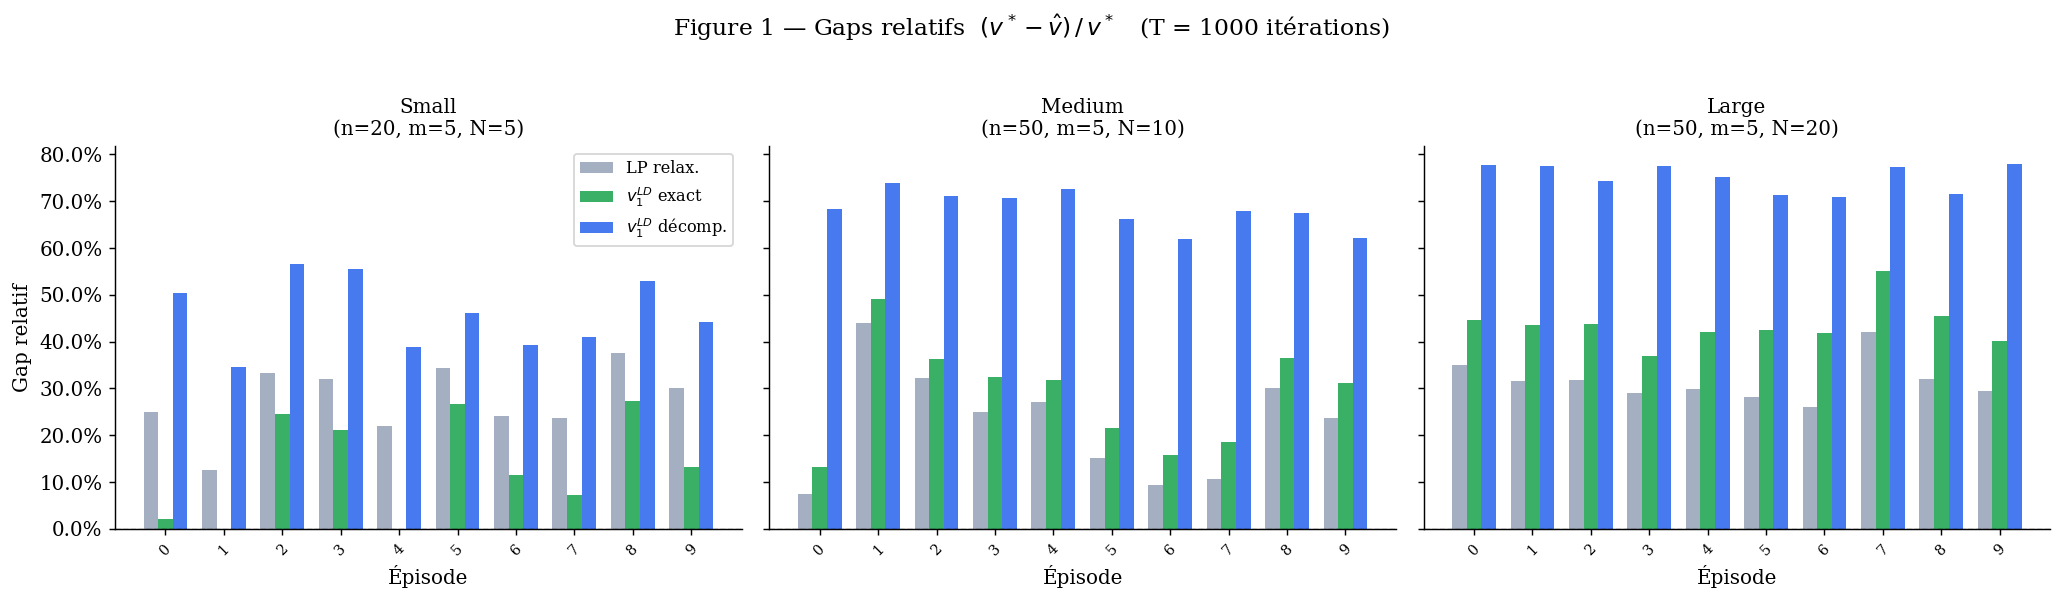

Sauvegardée : figures_cpp/fig1_quality_gaps.pdf


In [4]:
# ── Figure 1 — Gaps relatifs ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
fig.suptitle(
    r"Figure 1 — Gaps relatifs  $(v^* - \hat{v})\,/\,v^*$"
    f"   (T = {T_QUALITY} itérations)",
    fontsize=13, y=1.02
)

bar_labels = ["LP relax.", r"$v_1^{LD}$ exact", r"$v_1^{LD}$ décomp."]
bar_colors = ["#94a3b8",   "#16a34a",            "#2563eb"]
w = 0.25

for ax, (size, rows) in zip(axes, results_q.items()):
    x = np.arange(len(rows))
    gl = [max(r["gap_lp"],     0) for r in rows]
    ge = [max(r["gap_exact"],  0) for r in rows]
    gd = [max(r["gap_decomp"], 0) for r in rows]

    for i, (vals, col, lbl) in enumerate(zip([gl, ge, gd], bar_colors, bar_labels)):
        ax.bar(x + (i - 1) * w, vals, w, label=lbl, color=col, alpha=0.85)

    ax.axhline(0, color="k", lw=0.8, ls="--", alpha=0.4)
    inst0 = instances_all[size][0]
    ax.set_title(f"{size.capitalize()}\n(n={inst0.n}, m={inst0.m}, N={inst0.N})", fontsize=11)
    ax.set_xlabel("Épisode")
    ax.set_xticks(x)
    ax.set_xticklabels([str(r["ep"]) for r in rows], rotation=45, fontsize=8)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0, decimals=1))

axes[0].set_ylabel("Gap relatif")
axes[0].legend(fontsize=9, loc="upper right")

plt.tight_layout()
plt.savefig("figures_cpp/fig1_quality_gaps.pdf", bbox_inches="tight")
plt.savefig("figures_cpp/fig1_quality_gaps.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sauvegardée : figures_cpp/fig1_quality_gaps.pdf")

In [5]:
# ── Tableau récapitulatif 1 ──────────────────────────────────
summary_rows = []
for size, rows in results_q.items():
    inst0 = instances_all[size][0]
    summary_rows.append({
        "Taille":                size,
        "(n, m, N)":             f"({inst0.n}, {inst0.m}, {inst0.N})",
        "Gap LP (%)":            f"{np.mean([r['gap_lp']     for r in rows])*100:.2f}",
        "Gap DP exact (%)":      f"{np.mean([r['gap_exact']  for r in rows])*100:.2f}",
        "Gap DP décomp (%)":     f"{np.mean([r['gap_decomp'] for r in rows])*100:.2f}",
        "t décomp (s)":          f"{np.mean([r['time_decomp'] for r in rows]):.3f}",
        "t exact (s)":           f"{np.mean([r['time_exact']  for r in rows]):.3f}",
    })
df_q = pd.DataFrame(summary_rows).set_index("Taille")
display(df_q)

,"(n, m, N)",Gap LP (%),Gap DP exact (%),Gap DP décomp (%),t décomp (s),t exact (s)
Taille,,,,,,
small,"(20, 5, 5)",27.43,13.34,45.92,0.013,0.004
medium,"(50, 5, 10)",22.45,28.62,68.23,0.030,0.010
large,"(50, 5, 20)",31.47,43.59,75.13,0.064,0.023


## 2. Temps d'exécution en fonction du nombre d'itérations T

On fait varier $T \in \{10, 25, 50, 100, 200, 500, 1000\}$ et on mesure pour les deux variantes C++/DP :
- `v1LD décomp` (trait plein `—`) : décomposition interne ν, O(n·m) par itération
- `v1LD exact` (tirets `--`) : bitmask DP O(n·2^m) par itération, borne plus serrée
- `LP relax.` (pointillés `···`) : borne de référence, indépendant de T

In [6]:
timing_data = {}

for size in SIZES:
    print(f"\n── {size.upper()} ──")
    rows_q = results_q[size]

    t0 = time.perf_counter()
    for inst in instances_all[size]:
        solve_lp_relaxation_ccsp(inst)
    lp_time = (time.perf_counter() - t0) / len(instances_all[size])
    lp_gap  = np.mean([r["gap_lp"] for r in rows_q])
    print(f"  LP  : t_moy={lp_time:.4f}s   gap_moy={lp_gap*100:.2f}%")

    times_d, gaps_d = [], []
    times_e, gaps_e = [], []

    for T in T_VALUES:
        ts_d, gs_d = [], []
        ts_e, gs_e = [], []
        for inst, row in zip(instances_all[size], rows_q):
            denom = max(abs(row["v_mip"]), 1e-9)

            t0 = time.perf_counter()
            res_d = solve_cpp2(inst, T=T, decomp=True)
            ts_d.append(time.perf_counter() - t0)
            gs_d.append((row["v_mip"] - res_d["v1LD_star"]) / denom)

            t0 = time.perf_counter()
            res_e = solve_cpp2(inst, T=T, decomp=False)
            ts_e.append(time.perf_counter() - t0)
            gs_e.append((row["v_mip"] - res_e["v1LD_star"]) / denom)

        times_d.append(np.mean(ts_d)); gaps_d.append(np.mean(gs_d))
        times_e.append(np.mean(ts_e)); gaps_e.append(np.mean(gs_e))
        print(f"  T={T:5d}: décomp t={np.mean(ts_d):.4f}s gap={np.mean(gs_d)*100:.2f}%  |  "
              f"exact  t={np.mean(ts_e):.4f}s gap={np.mean(gs_e)*100:.2f}%")

    timing_data[size] = dict(
        times_d=times_d, gaps_d=gaps_d,
        times_e=times_e, gaps_e=gaps_e,
        lp_time=lp_time, lp_gap=lp_gap,
    )


── SMALL ──
  LP  : t_moy=0.0016s   gap_moy=27.43%
  T=   10: décomp t=0.0002s gap=80.57%  |  exact  t=0.0001s gap=44.83%
  T=   25: décomp t=0.0004s gap=75.57%  |  exact  t=0.0001s gap=29.06%
  T=   50: décomp t=0.0007s gap=71.70%  |  exact  t=0.0002s gap=22.36%
  T=  100: décomp t=0.0015s gap=67.09%  |  exact  t=0.0004s gap=18.75%
  T=  200: décomp t=0.0029s gap=61.98%  |  exact  t=0.0008s gap=15.79%
  T=  500: décomp t=0.0066s gap=53.44%  |  exact  t=0.0019s gap=14.23%
  T= 1000: décomp t=0.0132s gap=45.92%  |  exact  t=0.0038s gap=13.34%

── MEDIUM ──
  LP  : t_moy=0.0022s   gap_moy=22.45%
  T=   10: décomp t=0.0005s gap=85.56%  |  exact  t=0.0002s gap=63.25%
  T=   25: décomp t=0.0009s gap=83.88%  |  exact  t=0.0004s gap=61.13%
  T=   50: décomp t=0.0017s gap=81.47%  |  exact  t=0.0006s gap=54.86%
  T=  100: décomp t=0.0031s gap=78.43%  |  exact  t=0.0011s gap=45.01%
  T=  200: décomp t=0.0063s gap=75.51%  |  exact  t=0.0022s gap=37.05%
  T=  500: décomp t=0.0161s gap=71.61%  |  

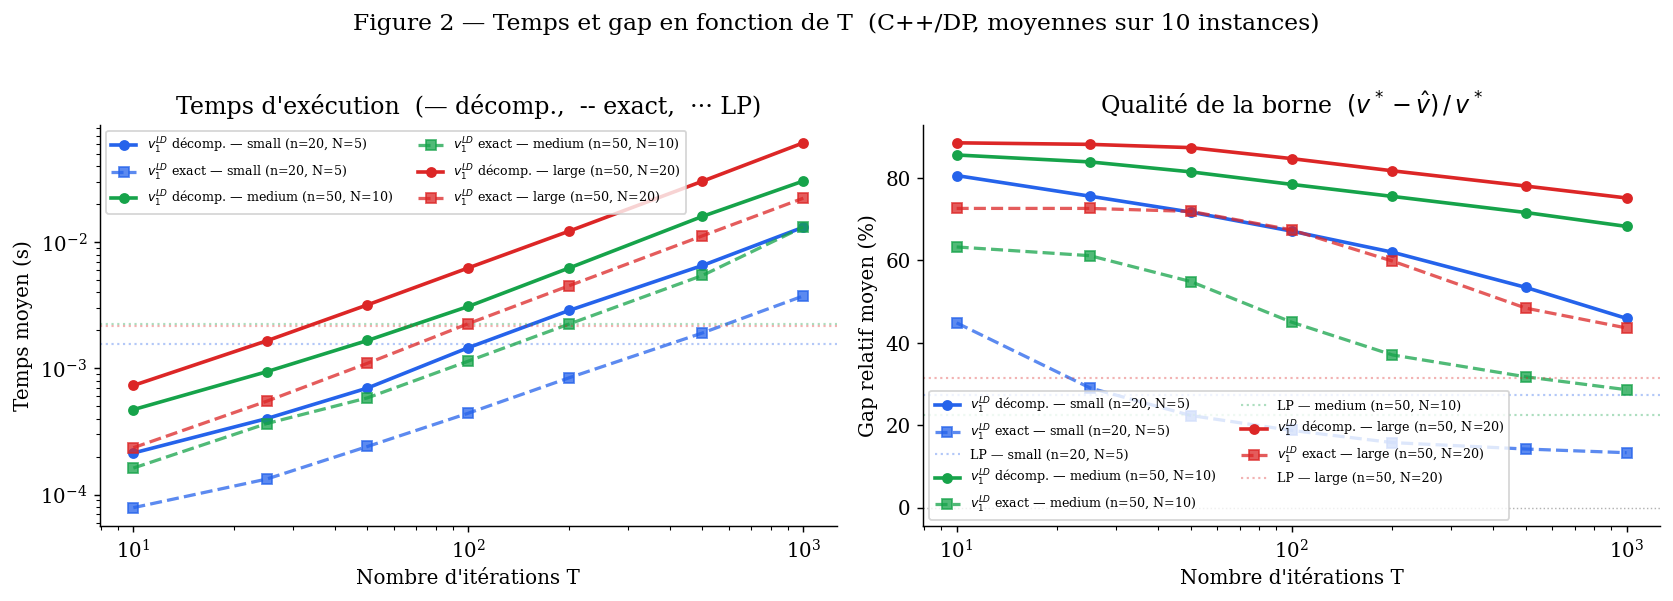

Sauvegardée : figures_cpp/fig2_timing_quality.pdf


In [7]:
# ── Figure 2 — Temps et qualité vs T ────────────────────────
fig, (ax_t, ax_g) = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle(
    r"Figure 2 — Temps et gap en fonction de T  (C++/DP, moyennes sur 10 instances)",
    fontsize=13, y=1.02
)
T_arr = np.array(T_VALUES)

for size, data in timing_data.items():
    c = PALETTE[size]
    inst0 = instances_all[size][0]
    lbl = f"{size} (n={inst0.n}, N={inst0.N})"

    ax_t.plot(T_arr, data["times_d"], "-o",  color=c, lw=2,   ms=5,             label=r"$v_1^{LD}$ décomp. — " + lbl)
    ax_t.plot(T_arr, data["times_e"], "--s", color=c, lw=1.8, ms=5, alpha=0.75, label=r"$v_1^{LD}$ exact — " + lbl)
    ax_t.axhline(data["lp_time"], color=c, ls=":", lw=1.2, alpha=0.35)

    ax_g.plot(T_arr, [g*100 for g in data["gaps_d"]], "-o",  color=c, lw=2,   ms=5,             label=r"$v_1^{LD}$ décomp. — " + lbl)
    ax_g.plot(T_arr, [g*100 for g in data["gaps_e"]], "--s", color=c, lw=1.8, ms=5, alpha=0.75, label=r"$v_1^{LD}$ exact — " + lbl)
    ax_g.axhline(data["lp_gap"]*100, color=c, ls=":", lw=1.2, alpha=0.35, label=f"LP — {lbl}")

for ax in (ax_t, ax_g):
    ax.set_xscale("log")
    ax.set_xlabel("Nombre d'itérations T")
    ax.legend(fontsize=7, ncol=2)

ax_t.set_yscale("log")
ax_t.set_ylabel("Temps moyen (s)")
ax_t.set_title(r"Temps d'exécution  (— décomp.,  -- exact,  ··· LP)")

ax_g.set_ylabel(r"Gap relatif moyen (%)")
ax_g.set_title(r"Qualité de la borne  $(v^* - \hat{v})\,/\,v^*$")
ax_g.axhline(0, color="k", lw=0.8, ls=":", alpha=0.3)

plt.tight_layout()
plt.savefig("figures_cpp/fig2_timing_quality.pdf", bbox_inches="tight")
plt.savefig("figures_cpp/fig2_timing_quality.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sauvegardée : figures_cpp/fig2_timing_quality.pdf")

## 3. Vitesse de convergence

Courbe $\text{gap}(t) = (v^* - v_{\text{best}}(t)) / v^*$ en fonction de l'itération $t$,
pour $v_1^{LD}$ décomp. (trait plein) et $v_1^{LD}$ exact (tirets),
sur $N_{\text{conv}} = 3$ instances par taille.

In [8]:
conv_data = {}

for size in SIZES:
    print(f"\n── {size.upper()} (T={T_CONV}) ──")
    size_runs = []
    for inst, row in zip(instances_all[size][:N_CONV], results_q[size][:N_CONV]):
        v_mip = row["v_mip"]
        denom = max(abs(v_mip), 1e-9)

        res_d = solve_cpp2(inst, T=T_CONV, decomp=True)
        best_d = np.maximum.accumulate(res_d["convergence"])
        gap_d  = np.maximum((v_mip - best_d) / denom, 0.0)

        res_e = solve_cpp2(inst, T=T_CONV, decomp=False)
        best_e = np.maximum.accumulate(res_e["convergence"])
        gap_e  = np.maximum((v_mip - best_e) / denom, 0.0)

        def iter_below(gap_arr, thresh=0.01):
            idx = np.argmax(gap_arr <= thresh)
            return idx if gap_arr[idx] <= thresh else T_CONV

        size_runs.append({
            "ep": inst.episode, "v_mip": v_mip,
            "gap_decomp": gap_d,
            "gap_exact":  gap_e,
        })
        print(f"  ep {inst.episode:3d}: v*={v_mip:.2f}  "
              f"décomp final={gap_d[-1]*100:.2f}% (1%@{iter_below(gap_d)})  |  "
              f"exact  final={gap_e[-1]*100:.2f}% (1%@{iter_below(gap_e)})")

    conv_data[size] = size_runs


── SMALL (T=2000) ──
  ep   0: v*=4.00  décomp final=39.02% (1%@2000)  |  exact  final=1.38% (1%@2000)
  ep   1: v*=4.00  décomp final=25.76% (1%@2000)  |  exact  final=0.00% (1%@135)
  ep   2: v*=3.00  décomp final=49.38% (1%@2000)  |  exact  final=23.91% (1%@2000)

── MEDIUM (T=2000) ──
  ep   0: v*=3.00  décomp final=63.52% (1%@2000)  |  exact  final=10.86% (1%@2000)
  ep   1: v*=3.00  décomp final=70.74% (1%@2000)  |  exact  final=47.08% (1%@2000)
  ep   2: v*=4.00  décomp final=66.77% (1%@2000)  |  exact  final=34.71% (1%@2000)

── LARGE (T=2000) ──
  ep   0: v*=5.00  décomp final=74.43% (1%@2000)  |  exact  final=41.34% (1%@2000)
  ep   1: v*=3.00  décomp final=74.74% (1%@2000)  |  exact  final=40.20% (1%@2000)
  ep   2: v*=5.00  décomp final=70.31% (1%@2000)  |  exact  final=40.40% (1%@2000)


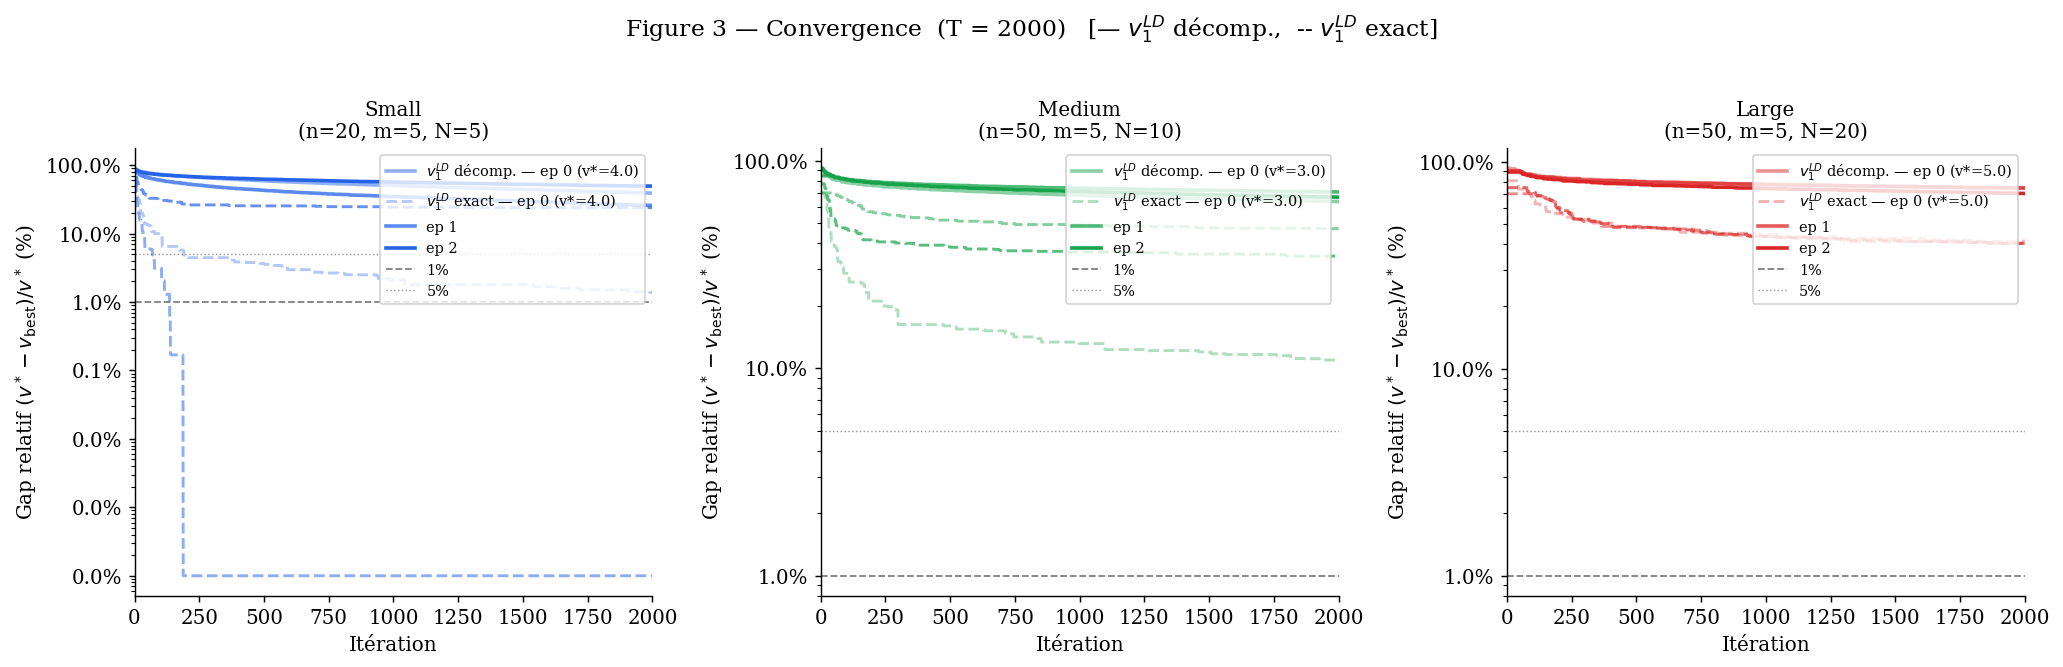

Sauvegardée : figures_cpp/fig3_convergence.pdf


In [9]:
# ── Figure 3 — Courbes de convergence ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5.0))
fig.suptitle(
    r"Figure 3 — Convergence  (T = " + str(T_CONV) + r")"
    r"   [— $v_1^{LD}$ décomp.,  -- $v_1^{LD}$ exact]",
    fontsize=13, y=1.02
)
iters = np.arange(1, T_CONV + 1)

for ax, (size, runs) in zip(axes, conv_data.items()):
    c = PALETTE[size]
    alphas = np.linspace(0.50, 1.0, len(runs))

    for k, run in enumerate(runs):
        alpha = alphas[k]
        lbl_base = f"ep {run['ep']} (v*={run['v_mip']:.1f})"

        gap_d_pct = np.maximum(run["gap_decomp"] * 100, 1e-4)
        gap_e_pct = np.maximum(run["gap_exact"]  * 100, 1e-4)

        kw_d = dict(color=c, alpha=alpha,       lw=2.0)
        kw_e = dict(color=c, alpha=alpha * 0.7, lw=1.6, linestyle="--")

        if k == 0:
            ax.semilogy(iters, gap_d_pct, **kw_d, label=r"$v_1^{LD}$ décomp. — " + lbl_base)
            ax.semilogy(iters, gap_e_pct, **kw_e, label=r"$v_1^{LD}$ exact — " + lbl_base)
        else:
            ax.semilogy(iters, gap_d_pct, **kw_d, label=f"ep {run['ep']}")
            ax.semilogy(iters, gap_e_pct, **kw_e, label="_nolegend_")

    ax.axhline(1.0, color="k", ls="--", lw=1.0, alpha=0.5, label="1%")
    ax.axhline(5.0, color="k", ls=":",  lw=0.8, alpha=0.4, label="5%")

    inst0 = instances_all[size][0]
    ax.set_title(f"{size.capitalize()}\n(n={inst0.n}, m={inst0.m}, N={inst0.N})", fontsize=11)
    ax.set_xlabel("Itération")
    ax.set_ylabel(r"Gap relatif $(v^* - v_\mathrm{best}) / v^*$ (%)")
    ax.set_xlim(0, T_CONV)
    ax.legend(fontsize=8, loc="upper right")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:.1f}%"))

plt.tight_layout()
plt.savefig("figures_cpp/fig3_convergence.pdf", bbox_inches="tight")
plt.savefig("figures_cpp/fig3_convergence.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sauvegardée : figures_cpp/fig3_convergence.pdf")

In [10]:
# ── Récapitulatif global ─────────────────────────────────────
print("\n====== RÉSUMÉ GLOBAL (C++/DP) ======")
summary_rows = []
for size in SIZES:
    rows  = results_q[size]
    data  = timing_data[size]
    inst0 = instances_all[size][0]
    summary_rows.append({
        "Taille":            size,
        "(n, m, N)":         f"({inst0.n}, {inst0.m}, {inst0.N})",
        "Gap LP (%)":        f"{np.mean([r['gap_lp']     for r in rows])*100:.2f}",
        "Gap exact (%)":     f"{np.mean([r['gap_exact']  for r in rows])*100:.2f}",
        "Gap décomp (%)":    f"{np.mean([r['gap_decomp'] for r in rows])*100:.2f}",
        "t décomp T=1000 (s)": f"{data['times_d'][-1]:.3f}",
        "t exact  T=1000 (s)": f"{data['times_e'][-1]:.3f}",
        "t LP (s)":          f"{data['lp_time']:.4f}",
    })
df_summary = pd.DataFrame(summary_rows).set_index("Taille")
display(df_summary)


====== RÉSUMÉ GLOBAL (C++/DP) ======


,"(n, m, N)",Gap LP (%),Gap exact (%),Gap décomp (%),t décomp T=1000 (s),t exact T=1000 (s),t LP (s)
Taille,,,,,,,
small,"(20, 5, 5)",27.43,13.34,45.92,0.013,0.004,0.0016
medium,"(50, 5, 10)",22.45,28.62,68.23,0.031,0.013,0.0022
large,"(50, 5, 20)",31.47,43.59,75.13,0.061,0.022,0.0022
